# 04 · Part C: where does adding a GLP-1 / SGLT2 drug pay for itself?

**Part C of the story**, and the answer to the client's question:

> *For which diabetic patients does adding a GLP-1 or SGLT2 drug pay for itself by preventing hospital stays?*

It combines the two earlier parts:

| Input | From | Value |
|---|---|---|
| How often each patient is in hospital | Part A, notebook 02 (hospital data): this stay + prior stays in the past 12 months | per patient |
| What a year of the drug costs | Part B, notebook 03 (CMS) and CMS negotiated prices | 4 price scenarios |
| How much the drug cuts hospital stays | EMPA-REG OUTCOME trial: all-cause hospitalization HR 0.89 → **11%** fewer (95% CI 4–18%) | `reference/assumptions.csv` |
| What a hospital stay costs Medicare | CMS Medicare inpatient payments (2024), moved to **2026 dollars** with the BLS hospital price index | section 0 below |

**The model, per patient per year**

```
admissions avoided  = expected admissions next year × 11%
savings             = admissions avoided × Medicare payment per admission (2026 $)
net value           = savings − annual drug cost        (positive = pays for itself)
break-even          = annual drug cost ÷ (11% × payment per admission)   admissions a year
```

**Key assumption, stated up front:** next year's admissions match the past 12 months (this stay plus prior stays). Frequent users tend to drift back toward average (regression to the mean), so I also test a version where next year is only **half** the past year.

This counts **only** hospital savings. Fewer deaths, slower kidney decline and better quality of life are real benefits of these drugs but aren't priced here, so the estimate is conservative.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import ROOT, PROCESSED, FIGURES, RESULTS, SERIES, MUTED, INK2, style, update_results
from src import apis
import json
style()

p = pd.read_parquet(PROCESSED / "patients_scored.parquet")
A = pd.read_csv(ROOT / "reference" / "assumptions.csv").set_index("parameter")
ANNUAL = json.loads(RESULTS.read_text())["lever"]["annual_cost"]      # from Part B (notebook 03)

RRR = A.loc["rrr_hospitalization", ["low", "base", "high"]].astype(float)
R_ALL = json.loads(RESULTS.read_text())

## 0. Reconciling the years

The inputs come from different years: hospital patients from **1999–2008**, Medicare drug data from **2013–2024**, the trial from **2015**, hospital costs from **2018/2024**, and negotiated prices for **2026/2027**. The client's decision is about **2026**, so:

1. **Every dollar is converted to 2026 dollars** with the BLS price index for inpatient hospital services.
2. **The cost of a stay is what Medicare pays**, from CMS's own 2024 inpatient data, so it matches the payer and the drug prices. The older AHRQ HCUP figure is kept only as a cross-check.
3. **The 1999–2008 hospital patterns are checked** against recent readmission rates, and the direction of any bias is stated.

In [2]:
inp = apis.cms_inpatient_national()
cpi = apis.bls_series(apis.CPI_INPATIENT, 2017, 2026)
level = cpi.groupby("year").value.mean()                   # 2026 = January-October average
to_2026 = lambda year: level[2026] / level[year]

def weighted_payment(d):
    return (d.Tot_Dschrgs * d.Avg_Tot_Pymt_Amt).sum() / d.Tot_Dschrgs.sum()

DIAB_HF = ["637", "638", "639", "291", "292", "293"]        # diabetes and heart-failure DRGs
pay_all_2024 = weighted_payment(inp)
pay_dhf_2024 = weighted_payment(inp[inp.DRG_Cd.isin(DIAB_HF)])
hcup_2018 = A.loc["cost_per_admission_hcup_2018", "base"]

recon = pd.DataFrame([
    {"measure": "Medicare payment per admission, all stays", "source": "CMS inpatient 2024", "original_year": 2024, "original_$": pay_all_2024},
    {"measure": "Medicare payment per admission, diabetes + heart-failure stays", "source": "CMS inpatient 2024", "original_year": 2024, "original_$": pay_dhf_2024},
    {"measure": "Average readmission cost, all payers (cross-check)", "source": "AHRQ HCUP 2018", "original_year": 2018, "original_$": hcup_2018},
])
recon["factor_to_2026"] = recon.original_year.map(to_2026)
recon["in_2026_$"] = recon["original_$"] * recon.factor_to_2026
recon.round(2)

,measure,source,original_year,original_$,factor_to_2026,in_2026_$
0,"Medicare payment per admission, all stays",CMS inpatient 2024,2024,18728.28,1.10,20654.42
1,"Medicare payment per admission, diabetes + hea...",CMS inpatient 2024,2024,11734.70,1.10,12941.57
2,"Average readmission cost, all payers (cross-ch...",AHRQ HCUP 2018,2018,15200.00,1.38,20929.66


In [3]:
COST = pd.Series({"low": recon["in_2026_$"][1], "base": recon["in_2026_$"][0], "high": max(recon["in_2026_$"][0], recon["in_2026_$"][2])})
print(f"Cost of an admission to Medicare in 2026 dollars: base ${COST['base']:,.0f} (all stays), low ${COST['low']:,.0f} (diabetes/heart-failure stays), high ${COST['high']:,.0f}")
print(f"Price index rise: 2018→2026 {to_2026(2018)-1:.0%}, 2024→2026 {to_2026(2024)-1:.0%}")

Cost of an admission to Medicare in 2026 dollars: base $20,654 (all stays), low $12,942 (diabetes/heart-failure stays), high $20,930
Price index rise: 2018→2026 38%, 2024→2026 10%


The two independent sources agree once they're in the same year: Medicare's 2024 all-stay payment and AHRQ's 2018 all-payer readmission cost both come to roughly **$21,000 in 2026 dollars**. Diabetes and heart-failure stays specifically are cheaper (about $13,000), so that's the low case.

In [4]:
C1 = R_ALL["cleaning"]
bench = A.loc["benchmark_readmission_diabetes", ["low", "high"]].astype(float)
check = pd.DataFrame([
    {"measure": "30-day readmission, every stay (1999–2008 data)", "value_pct": 100 * C1["readmit_rate_all_stays"]},
    {"measure": "30-day readmission, first stay per patient (used here)", "value_pct": 100 * C1["readmit_rate"]},
    {"measure": "Recent US studies of hospitalized diabetic patients (Rubin & Shah 2021)", "value_pct": f"{100*bench['low']:.1f}–{100*bench['high']:.1f}"},
])
check

,measure,value_pct
0,"30-day readmission, every stay (1999–2008 data)",11.39
1,"30-day readmission, first stay per patient (us...",8.98
2,Recent US studies of hospitalized diabetic pat...,16.0–20.4


In [5]:
TIME = pd.DataFrame([
    {"input": "Hospital stays per patient", "data_year": "1999–2008", "how_aligned": "Kept as a pattern; checked against recent readmission rates; 50% scenario",
     "effect_on_result": "Likely understates value: readmissions in this data run below recent rates"},
    {"input": "Drug effect (11%)", "data_year": "2015 trial", "how_aligned": "Biological effect, not a price; range 4–18%",
     "effect_on_result": "Neutral; real-world adherence could lower it"},
    {"input": "Cost of an admission", "data_year": "2024 (CMS), 2018 (HCUP)", "how_aligned": "Converted to 2026 $ with the BLS inpatient-hospital price index",
     "effect_on_result": "Fixed: was understated by mixing 2018 costs with 2026 prices"},
    {"input": "Negotiated drug prices", "data_year": "2026 / 2027", "how_aligned": "Already the decision year",
     "effect_on_result": "Neutral (GLP-1 price is one year later)"},
    {"input": "Gross drug cost", "data_year": "2024", "how_aligned": "Left in 2024 $, used only as a comparison scenario",
     "effect_on_result": "Slightly understates gross cost if list prices rose"},
    {"input": "Use trend", "data_year": "2013–2024", "how_aligned": "One consistent CMS file every year",
     "effect_on_result": "Context only"},
])
TIME

,input,data_year,how_aligned,effect_on_result
0,Hospital stays per patient,1999–2008,Kept as a pattern; checked against recent read...,Likely understates value: readmissions in this...
1,Drug effect (11%),2015 trial,"Biological effect, not a price; range 4–18%",Neutral; real-world adherence could lower it
2,Cost of an admission,"2024 (CMS), 2018 (HCUP)",Converted to 2026 $ with the BLS inpatient-hos...,Fixed: was understated by mixing 2018 costs wi...
3,Negotiated drug prices,2026 / 2027,Already the decision year,Neutral (GLP-1 price is one year later)
4,Gross drug cost,2024,"Left in 2024 $, used only as a comparison scen...",Slightly understates gross cost if list prices...
5,Use trend,2013–2024,One consistent CMS file every year,Context only


## 1. The break-even point

How many hospital admissions a year a patient needs for the drug to pay for itself, for each price.

In [6]:
breakeven = pd.Series({k: v / (RRR["base"] * COST["base"]) for k, v in ANNUAL.items()}).round(2)
be = pd.DataFrame({"annual drug cost ($)": pd.Series(ANNUAL), "break-even admissions / year": breakeven})
be

,annual drug cost ($),break-even admissions / year
SGLT2 · negotiated (2026),2364,1.04
GLP-1 · negotiated (2027),3288,1.45
SGLT2 · gross 2024,6481,2.85
GLP-1 · gross 2024,11313,4.98


At the **negotiated SGLT2 price**, a patient needs about **1.04 admissions a year** for the drug to pay for itself; at **gross 2024 prices**, about **2.85**. Every patient in this data has at least one admission in the past year (the stay that put them in the data), so first-time patients sit just below break-even, and anyone with **another** stay clears it.

## 2. Who clears it: patients grouped by hospital stays in the past year

In [7]:
p["past12"] = p.admits_past_12m
p["stays_group"] = pd.cut(p.number_inpatient, [-1, 0, 1, 2, 100], labels=["This stay only", "1 prior stay", "2 prior stays", "3+ prior stays"])

def net_value(admits, annual_cost, rrr=RRR["base"], cost=COST["base"], factor=1.0):
    return admits * factor * rrr * cost - annual_cost

grp = (p.groupby("stays_group", observed=True)
         .agg(patients=("past12", "size"), admits_past_12m=("past12", "mean"),
              readmit_30_pct=("readmit_30", "mean"), heart_pct=("has_heart_dx", "mean")))
grp["share_pct"] = 100 * grp.patients / len(p)
for k, v in ANNUAL.items():
    grp[k] = net_value(grp.admits_past_12m, v)
grp["readmit_30_pct"] *= 100; grp["heart_pct"] *= 100
grp.round(1)

,patients,admits_past_12m,readmit_30_pct,heart_pct,share_pct,SGLT2 · negotiated (2026),GLP-1 · negotiated (2027),SGLT2 · gross 2024,GLP-1 · gross 2024
stays_group,,,,,,,,,
This stay only,61792,1.0,8.1,57.9,88.3,-92.0,-1016.0,-4209.0,-9041.0
1 prior stay,5798,2.0,12.9,60.6,8.3,2180.0,1256.0,-1937.0,-6769.0
2 prior stays,1501,3.0,18.5,62.0,2.1,4452.0,3528.0,335.0,-4497.0
3+ prior stays,896,4.9,26.5,57.9,1.3,8876.8,7952.8,4759.8,-72.2


**Net value per patient-year** (positive = pays for itself). At negotiated prices, an SGLT2 drug pays for itself for patients with **at least one other hospital stay in the past year** (about +$2,200 a year with one prior stay, rising with each additional stay). First-time patients are **roughly break-even** (about −$90 a year). A GLP-1 at its negotiated price pays for itself from one prior stay. At gross 2024 prices, SGLT2 pays only for patients with 2+ prior stays, and GLP-1 never quite does.

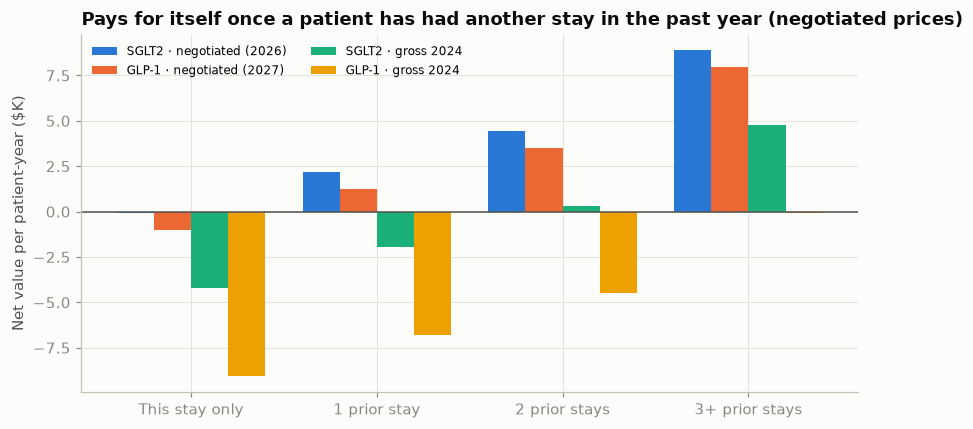

In [8]:
order = ["SGLT2 · negotiated (2026)", "GLP-1 · negotiated (2027)", "SGLT2 · gross 2024", "GLP-1 · gross 2024"]
x = np.arange(len(grp)); w = 0.2
fig, ax = plt.subplots(figsize=(8, 4))
for i, k in enumerate(order):
    ax.bar(x + (i - 1.5) * w, grp[k] / 1000, w, color=SERIES[i], label=k)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, grp.index); ax.set_ylabel("Net value per patient-year ($K)")
ax.set_title("Pays for itself once a patient has had another stay in the past year (negotiated prices)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIGURES / "04_net_value.png", dpi=160); plt.show()

## 3. The rule: "another hospital stay in the past year"

Turning the table into a decision rule a payer or hospital can apply at discharge, and sizing it **per 1,000 diabetic discharges**.

In [9]:
def rule_summary(annual_cost, factor=1.0, rrr=RRR["base"], cost=COST["base"]):
    q = p[p.number_inpatient >= 1]
    n = 1000 * len(q) / len(p)
    avoided = n * q.past12.mean() * factor * rrr
    net = n * net_value(q.past12.mean(), annual_cost, rrr, cost, factor)
    return {"qualifying per 1,000 discharges": n, "admissions avoided / yr": avoided,
            "drug cost / yr ($)": n * annual_cost, "hospital savings / yr ($)": avoided * cost, "net / yr ($)": net,
            "cost per admission avoided ($)": n * annual_cost / avoided}

rule = pd.DataFrame({k: rule_summary(v) for k, v in ANNUAL.items()}).T
rule.round(0)

,"qualifying per 1,000 discharges",admissions avoided / yr,drug cost / yr ($),hospital savings / yr ($),net / yr ($),cost per admission avoided ($)
SGLT2 · negotiated (2026),117.0,32.0,276808.0,666530.0,389721.0,8578.0
GLP-1 · negotiated (2027),117.0,32.0,385002.0,666530.0,281527.0,11930.0
SGLT2 · gross 2024,117.0,32.0,758881.0,666530.0,-92351.0,23516.0
GLP-1 · gross 2024,117.0,32.0,1324675.0,666530.0,-658145.0,41049.0


In [10]:
q = p[p.number_inpatient >= 1]
rest = p[p.number_inpatient == 0]
print(f"Qualifying patients: {len(q):,} of {len(p):,} ({len(q)/len(p):.1%})")
print(f"  30-day readmission: {q.readmit_30.mean():.1%} vs {rest.readmit_30.mean():.1%} for everyone else")
print(f"  heart or circulatory diagnosis: {q.has_heart_dx.mean():.1%}; kidney diagnosis: {q.has_kidney_dx.mean():.1%}")
print(f"  share of all 30-day readmissions that come from this group: {q.readmit_30.sum() / p.readmit_30.sum():.1%}")
print(f"  in the top 2 risk deciles from notebook 04: {(q.risk_decile >= 9).mean():.1%}")

Qualifying patients: 8,195 of 69,987 (11.7%)
  30-day readmission: 15.4% vs 8.1% for everyone else
  heart or circulatory diagnosis: 60.6%; kidney diagnosis: 15.3%
  share of all 30-day readmissions that come from this group: 20.1%
  in the top 2 risk deciles from notebook 04: 57.5%


## 3b. Should the client use the simple rule or the readmission model?

Part A built a readmission model. Here it competes with the one-line rule on the client's actual question. Both pick the **same number of patients** (11.7%): the rule takes everyone with another stay in the past year; the model takes the 11.7% with the highest predicted 30-day readmission risk.

In [11]:
k = len(q)
by_model = p.nlargest(k, "risk_score")
cmp = pd.DataFrame([
    {"selection": "Rule: another stay in the past year", "patients": k, "stays_per_year": q.past12.mean(),
     "readmit_30_pct": 100 * q.readmit_30.mean(), "share_of_30d_readmissions_pct": 100 * q.readmit_30.sum() / p.readmit_30.sum(),
     "net_per_patient_year": net_value(q.past12.mean(), ANNUAL["SGLT2 · negotiated (2026)"])},
    {"selection": "Model: top 11.7% predicted risk", "patients": k, "stays_per_year": by_model.past12.mean(),
     "readmit_30_pct": 100 * by_model.readmit_30.mean(), "share_of_30d_readmissions_pct": 100 * by_model.readmit_30.sum() / p.readmit_30.sum(),
     "net_per_patient_year": net_value(by_model.past12.mean(), ANNUAL["SGLT2 · negotiated (2026)"])},
]).round(2)
overlap = len(set(by_model.index) & set(q.index)) / k
print(f"Patients picked by both: {overlap:.0%}")
cmp

Patients picked by both: 37%


,selection,patients,stays_per_year,readmit_30_pct,share_of_30d_readmissions_pct,net_per_patient_year
0,Rule: another stay in the past year,8195,2.51,15.40,20.08,3328.30
1,Model: top 11.7% predicted risk,8195,1.74,19.63,25.60,1582.52


**The rule wins on this question.** The model is tuned to catch **30-day** readmissions, and it does (more of them, at a higher rate). But the drug's value depends on **how many stays a year** a patient has, and the rule picks patients with far more of those, so it delivers about twice the net value per patient. Practical bonus: a payer can apply the rule in any claims system without a model. The model still has a use: a 30-day post-discharge program, which is a different decision.

## 4. How sure are we? Sensitivity analysis

Net value for the qualifying group at the **negotiated SGLT2 price**, moving one assumption at a time between its low and high value (tornado), then a grid of the two biggest drivers.

In [12]:
base_cost = ANNUAL["SGLT2 · negotiated (2026)"]
qm = q.past12.mean()
base = net_value(qm, base_cost)
tornado = pd.DataFrame([
    {"assumption": "Hospitalization reduction (4% – 18%)", "low": net_value(qm, base_cost, rrr=RRR["low"]), "high": net_value(qm, base_cost, rrr=RRR["high"])},
    {"assumption": f"Cost per admission (${COST['low']:,.0f} – ${COST['high']:,.0f})", "low": net_value(qm, base_cost, cost=COST["low"]), "high": net_value(qm, base_cost, cost=COST["high"])},
    {"assumption": "Future admissions (50% – 100% of past year)", "low": net_value(qm, base_cost, factor=0.5), "high": base},
    {"assumption": "Price (negotiated – gross 2024)", "low": net_value(qm, ANNUAL["SGLT2 · gross 2024"]), "high": base},
]).assign(swing=lambda d: (d.high - d.low).abs()).sort_values("swing", ascending=False)
print(f"Base case net value per qualifying patient-year: ${base:,.0f}")
tornado.round(0)

Base case net value per qualifying patient-year: $3,328


,assumption,low,high,swing
0,Hospitalization reduction (4% – 18%),-294.0,6951.0,7245.0
3,Price (negotiated – gross 2024),-789.0,3328.0,4117.0
2,Future admissions (50% – 100% of past year),482.0,3328.0,2846.0
1,"Cost per admission ($12,942 – $20,930)",1203.0,3404.0,2201.0


In [13]:
rrr_grid = [0.04, 0.08, 0.11, 0.14, 0.18]
cost_grid = [int(round(COST["low"], -2)), 16000, int(round(COST["base"], -2)), 25000]
grid = pd.DataFrame([[100 * (net_value(p.past12, base_cost, r, c) > 0).mean() for c in cost_grid] for r in rrr_grid],
                    index=[f"{r:.0%}" for r in rrr_grid], columns=[f"${c:,}" for c in cost_grid])
grid.index.name = "hospitalization reduction ↓ / admission cost →"
grid.round(1)

,"$12,900","$16,000","$20,700","$25,000"
hospitalization reduction ↓ / admission cost →,,,,
4%,0.6,1.3,3.4,3.4
8%,3.4,11.7,11.7,11.7
11%,11.7,11.7,11.7,100.0
14%,11.7,11.7,100.0,100.0
18%,11.7,100.0,100.0,100.0


**Reading the sensitivity.** The result is most sensitive to **how big the hospitalization effect really is** and to **price**. The qualifying group stays positive if future admissions are only half the past year, or if a stay costs only what diabetes and heart-failure stays cost. It turns negative only at the bottom of the trial's effect range (4%) or at gross 2024 prices. The grid shows the share of **all** diabetic inpatients for whom the drug pays for itself under each combination. The next cell checks the narrower group with **2+** prior stays.

In [14]:
def stress(q):
    m = q.past12.mean()
    return {"base": net_value(m, base_cost), "effect 4%": net_value(m, base_cost, rrr=RRR["low"]),
            "admission cost (diabetes/HF stays)": net_value(m, base_cost, cost=COST["low"]), "future = 50% of past": net_value(m, base_cost, factor=0.5),
            "gross 2024 price": net_value(m, ANNUAL["SGLT2 · gross 2024"])}
STRESS = pd.DataFrame({"1+ prior stays": stress(p[p.number_inpatient >= 1]), "2+ prior stays": stress(p[p.number_inpatient >= 2]),
                       "1+ prior stays, Medicare age (70+)": stress(p[(p.number_inpatient >= 1) & (p.age_mid >= 75)])}).T.round(0)
STRESS

,base,effect 4%,admission cost (diabetes/HF stays),future = 50% of past,gross 2024 price
1+ prior stays,3328.0,-294.0,1203.0,482.0,-789.0
2+ prior stays,6106.0,716.0,2943.0,1871.0,1989.0
"1+ prior stays, Medicare age (70+)",3250.0,-323.0,1154.0,443.0,-867.0


**Patients with 2+ prior stays** stay positive in **every** single-assumption test, including gross prices and the lowest trial effect. That's the group to lead a pilot with. The broader 1+ group is positive in the base case and in two of the four tests. **Restricting to Medicare-age patients (70+)** barely changes anything: the hospital data covers all ages, but the answer holds for the population the client cares about.

## 4b. GLP-1 drugs: what effect would they need?

The 11% comes from an **SGLT2** trial (EMPA-REG). GLP-1 trials report fewer heart attacks and heart-failure admissions, but not a comparable all-cause hospitalization estimate, so instead of assuming one I ask the reverse question: how big would the effect need to be for a GLP-1 at its negotiated price to pay for itself?

In [15]:
glp1_cost = ANNUAL["GLP-1 · negotiated (2027)"]
needed = pd.Series({
    "1+ prior stays": glp1_cost / (q.past12.mean() * COST["base"]),
    "2+ prior stays": glp1_cost / (p[p.number_inpatient >= 2].past12.mean() * COST["base"]),
    "First-time patients": glp1_cost / (1.0 * COST["base"]),
}).rename("all-cause hospitalization reduction needed")
(100 * needed).round(1).astype(str) + "%"

1+ prior stays          6.4%
2+ prior stays          4.3%
First-time patients    15.9%
Name: all-cause hospitalization reduction needed, dtype: object

For patients with another stay in the past year, a GLP-1 at its negotiated price needs only about a **6% reduction** in hospital stays to pay for itself, half the SGLT2 trial's 11%. For first-time patients it would need about 16%, above anything the trials show.

In [16]:
half = pd.DataFrame({k: rule_summary(v, factor=0.5) for k, v in ANNUAL.items()}).T
two_plus = p[p.number_inpatient >= 2]
first = p[p.number_inpatient == 0]
update_results("value", {
    "assumptions": A.reset_index().fillna("").to_dict("records"),
    "cost": {k: round(v) for k, v in COST.items()}, "reconcile": recon.round(2).to_dict("records"), "time_table": TIME.to_dict("records"),
    "cpi_2018_2026": round(to_2026(2018) - 1, 3), "cpi_2024_2026": round(to_2026(2024) - 1, 3),
    "benchmark": {"all_stays": round(100 * C1["readmit_rate_all_stays"], 1), "first_stay": round(100 * C1["readmit_rate"], 1),
                  "recent_low": round(100 * bench["low"], 1), "recent_high": round(100 * bench["high"], 1)},
    "first_time_net": {k: round(float(net_value(1.0, v))) for k, v in ANNUAL.items()},
    "rule_vs_model": cmp.to_dict("records"), "rule_model_overlap": round(100 * overlap, 1),
    "glp1_needed": {k: round(100 * x, 1) for k, x in needed.items()},
    "annual_cost": ANNUAL,
    "breakeven": breakeven.to_dict(),
    "groups": grp.reset_index().astype({"stays_group": str}).round(1).to_dict("records"),
    "rule": rule.reset_index().rename(columns={"index": "scenario"}).round(0).to_dict("records"),
    "rule_half": half.reset_index().rename(columns={"index": "scenario"}).round(0).to_dict("records"),
    "qualifying": {"n": int(len(q)), "pct": round(100 * len(q) / len(p), 1), "readmit_30": round(100 * q.readmit_30.mean(), 1),
                   "readmit_30_rest": round(100 * rest.readmit_30.mean(), 1), "heart_pct": round(100 * q.has_heart_dx.mean(), 1),
                   "kidney_pct": round(100 * q.has_kidney_dx.mean(), 1),
                   "share_of_readmissions": round(100 * q.readmit_30.sum() / p.readmit_30.sum(), 1),
                   "mean_admits": round(qm, 2), "two_plus_pct": round(100 * len(two_plus) / len(p), 1)},
    "base_net": round(base), "tornado": tornado.round(0).to_dict("records"),
    "stress": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in STRESS.T.to_dict().items()},
    "grid": {"rrr": rrr_grid, "cost": cost_grid, "values": grid.round(1).values.tolist()},
})
print("saved")

saved
